In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("LED Energy Efficiency Project")
print("All libraries imported successfully!")

LED Energy Efficiency Project
All libraries imported successfully!


In [4]:
# Load the three original datasets

dataset1 = pd.read_csv("../data/raw/led_vs_incandescent_efficiency.csv")

dataset2 = pd.read_csv("../data/raw/led_vs_incandescent_efficiency_dataset_v2.csv")

dataset3 = pd.read_csv("../data/raw/led_vs_incandescent_energy_to_light_efficiency.csv")

print("All three datasets loaded successfully!")

All three datasets loaded successfully!


In [5]:
print("Dataset 1:", dataset1.shape)
print("Dataset 2:", dataset2.shape)
print("Dataset 3:", dataset3.shape)

Dataset 1: (33, 13)
Dataset 2: (300, 24)
Dataset 3: (200, 13)


In [6]:
print("========== DATASET 1 ==========")
print(dataset1.columns.tolist())

print("\n========== DATASET 2 ==========")
print(dataset2.columns.tolist())

print("\n========== DATASET 3 ==========")
print(dataset3.columns.tolist())

========== DATASET 1 ==========
['bulb_id', 'technology', 'rated_watts', 'lumens', 'cct_k', 'cri', 'rated_life_hours', 'equivalent_incandescent_w', 'efficacy_lm_per_w', 'luminous_efficiency_pct', 'energy_per_1000h_kwh', 'watts_to_deliver_800lm', 'cost_per_klm_hour_usd_at_0.16_per_kwh']

========== DATASET 2 ==========
['bulb_type', 'rated_brightness_lumens', 'power_consumption_watts', 'luminous_efficacy_lm_per_w', 'color_temperature_kelvin', 'color_rendering_index_cri', 'supply_voltage_volts', 'power_factor', 'heat_output_relative_index', 'estimated_lifespan_hours', 'purchase_price_inr', 'dimmable', 'warmup_time_seconds', 'flicker_index_percent', 'beam_angle_degrees', 'daily_usage_hours', 'operating_days_per_year', 'annual_energy_kwh', 'annual_electricity_cost_inr', 'annual_co2_emissions_kg', 'estimated_five_year_total_cost_inr', 'ambient_temperature_celsius', 'electricity_tariff_assumption_inr_per_kwh', 'grid_emission_factor_assumption_kg_per_kwh']

========== DATASET 3 ==========
['b

In [7]:
dataset3.head(10)

,bulb_type,target_brightness_lumens,measured_brightness_lumens,power_rating_watts,luminous_efficacy_lumens_per_watt,usage_hours_per_day,daily_energy_consumption_wh,annual_energy_consumption_kwh,estimated_annual_electricity_cost_inr,estimated_lifespan_hours,estimated_annual_co2_emissions_kg,electricity_tariff_inr_per_kwh_assumption,grid_emission_factor_kg_co2_per_kwh_assumption
0,LED,1600,1568.6,16.32,96.12,2,32.64,11.913,95.30,24067,8.339,8.0,0.7
1,LED,450,427.3,4.89,87.41,6,29.33,10.705,85.64,24153,7.493,8.0,0.7
2,LED,800,776.5,8.76,88.63,2,17.52,6.396,51.16,23289,4.477,8.0,0.7
3,Incandescent,1100,1052.8,73.02,14.42,8,584.20,213.231,1705.85,1084,149.262,8.0,0.7
4,Incandescent,800,807.6,58.59,13.78,4,234.36,85.542,684.34,1158,59.880,8.0,0.7
5,Incandescent,450,462.9,33.34,13.89,8,266.68,97.340,778.72,915,68.138,8.0,0.7
6,LED,1100,1220.1,14.11,86.45,8,112.91,41.213,329.70,24047,28.849,8.0,0.7
7,Incandescent,1100,1237.8,87.43,14.16,8,699.46,255.303,2042.42,853,178.712,8.0,0.7
8,Incandescent,1100,1077.3,75.12,14.34,4,300.48,109.675,877.40,923,76.772,8.0,0.7
9,LED,800,738.5,8.58,86.09,2,17.16,6.262,50.10,22867,4.383,8.0,0.7


In [8]:
# Check missing values
print("MISSING VALUES")
print(dataset3.isnull().sum())

# Check duplicate records
print("\nDUPLICATE RECORDS")
print(dataset3.duplicated().sum())

# Check data types
print("\nDATA TYPES")
print(dataset3.dtypes)

# Check LED and Incandescent record counts
print("\nBULB TYPE COUNTS")
print(dataset3["bulb_type"].value_counts())

MISSING VALUES
bulb_type                                         0
target_brightness_lumens                          0
measured_brightness_lumens                        0
power_rating_watts                                0
luminous_efficacy_lumens_per_watt                 0
usage_hours_per_day                               0
daily_energy_consumption_wh                       0
annual_energy_consumption_kwh                     0
estimated_annual_electricity_cost_inr             0
estimated_lifespan_hours                          0
estimated_annual_co2_emissions_kg                 0
electricity_tariff_inr_per_kwh_assumption         0
grid_emission_factor_kg_co2_per_kwh_assumption    0
dtype: int64

DUPLICATE RECORDS
0

DATA TYPES
bulb_type                                          object
target_brightness_lumens                            int64
measured_brightness_lumens                        float64
power_rating_watts                                float64
luminous_efficacy_lumens_per_wa

In [9]:
# Recalculate luminous efficacy
dataset3["calculated_efficacy"] = (
    dataset3["measured_brightness_lumens"] /
    dataset3["power_rating_watts"]
)

# Recalculate daily energy
dataset3["calculated_daily_energy_wh"] = (
    dataset3["power_rating_watts"] *
    dataset3["usage_hours_per_day"]
)

# Recalculate annual energy
dataset3["calculated_annual_energy_kwh"] = (
    dataset3["calculated_daily_energy_wh"] * 365 / 1000
)

# Compare calculated and existing values
print("EFFICACY MATCH:",
      np.allclose(dataset3["calculated_efficacy"],
                  dataset3["luminous_efficacy_lumens_per_watt"],
                  atol=0.02))

print("DAILY ENERGY MATCH:",
      np.allclose(dataset3["calculated_daily_energy_wh"],
                  dataset3["daily_energy_consumption_wh"],
                  atol=0.02))

print("ANNUAL ENERGY MATCH:",
      np.allclose(dataset3["calculated_annual_energy_kwh"],
                  dataset3["annual_energy_consumption_kwh"],
                  atol=0.002))

EFFICACY MATCH: False
DAILY ENERGY MATCH: False
ANNUAL ENERGY MATCH: False


In [10]:
# Calculate the differences between existing and recalculated values

dataset3["efficacy_difference"] = abs(
    dataset3["luminous_efficacy_lumens_per_watt"]
    - dataset3["calculated_efficacy"]
)

dataset3["daily_energy_difference"] = abs(
    dataset3["daily_energy_consumption_wh"]
    - dataset3["calculated_daily_energy_wh"]
)

dataset3["annual_energy_difference"] = abs(
    dataset3["annual_energy_consumption_kwh"]
    - dataset3["calculated_annual_energy_kwh"]
)

# Count records with differences beyond our tolerances

print("EFFICACY MISMATCHES:",
      (dataset3["efficacy_difference"] > 0.02).sum())

print("DAILY ENERGY MISMATCHES:",
      (dataset3["daily_energy_difference"] > 0.02).sum())

print("ANNUAL ENERGY MISMATCHES:",
      (dataset3["annual_energy_difference"] > 0.002).sum())

# Display records with efficacy differences
print("\nEFFICACY MISMATCH EXAMPLES")

display(
    dataset3.loc[
        dataset3["efficacy_difference"] > 0.02,
        ["bulb_type", "measured_brightness_lumens",
         "power_rating_watts",
         "luminous_efficacy_lumens_per_watt",
         "calculated_efficacy"]
    ].head(5)
)

# Display records with daily energy differences
print("\nDAILY ENERGY MISMATCH EXAMPLES")

display(
    dataset3.loc[
        dataset3["daily_energy_difference"] > 0.02,
        ["bulb_type", "power_rating_watts",
         "usage_hours_per_day",
         "daily_energy_consumption_wh",
         "calculated_daily_energy_wh"]
    ].head(5)
)

EFFICACY MISMATCHES: 54
DAILY ENERGY MISMATCHES: 46
ANNUAL ENERGY MISMATCHES: 141

EFFICACY MISMATCH EXAMPLES


,bulb_type,measured_brightness_lumens,power_rating_watts,luminous_efficacy_lumens_per_watt,calculated_efficacy
1,LED,427.3,4.89,87.41,87.382413
6,LED,1220.1,14.11,86.45,86.470588
10,LED,1049.2,11.98,87.61,87.579299
19,LED,890.0,10.39,85.70,85.659288
21,LED,424.1,4.90,86.49,86.551020



DAILY ENERGY MISMATCH EXAMPLES


,bulb_type,power_rating_watts,usage_hours_per_day,daily_energy_consumption_wh,calculated_daily_energy_wh
3,Incandescent,73.02,8,584.20,584.16
5,Incandescent,33.34,8,266.68,266.72
6,LED,14.11,8,112.91,112.88
10,LED,11.98,8,95.81,95.84
17,Incandescent,86.57,4,346.30,346.28


In [11]:
print("EFFICACY DIFFERENCE")
print("Maximum:", dataset3["efficacy_difference"].max())
print("Average:", dataset3["efficacy_difference"].mean())

print("\nDAILY ENERGY DIFFERENCE")
print("Maximum:", dataset3["daily_energy_difference"].max())
print("Average:", dataset3["daily_energy_difference"].mean())

print("\nANNUAL ENERGY DIFFERENCE")
print("Maximum:", dataset3["annual_energy_difference"].max())
print("Average:", dataset3["annual_energy_difference"].mean())

EFFICACY DIFFERENCE
Maximum: 0.09463276836157775
Average: 0.014473439829742318

DAILY ENERGY DIFFERENCE
Maximum: 0.04000000000007731
Average: 0.012750000000002473

ANNUAL ENERGY DIFFERENCE
Maximum: 0.014800000000001035
Average: 0.004635999999999734


In [12]:
# Recalculate all derived values

dataset3["luminous_efficacy_lumens_per_watt"] = (
    dataset3["measured_brightness_lumens"] /
    dataset3["power_rating_watts"]
)

dataset3["daily_energy_consumption_wh"] = (
    dataset3["power_rating_watts"] *
    dataset3["usage_hours_per_day"]
)

dataset3["annual_energy_consumption_kwh"] = (
    dataset3["daily_energy_consumption_wh"] * 365 / 1000
)

dataset3["estimated_annual_electricity_cost_inr"] = (
    dataset3["annual_energy_consumption_kwh"] *
    dataset3["electricity_tariff_inr_per_kwh_assumption"]
)

dataset3["estimated_annual_co2_emissions_kg"] = (
    dataset3["annual_energy_consumption_kwh"] *
    dataset3["grid_emission_factor_kg_co2_per_kwh_assumption"]
)

print("Derived columns recalculated successfully!")

Derived columns recalculated successfully!


In [15]:
print("EFFICACY VERIFIED:",
      np.allclose(
          dataset3["luminous_efficacy_lumens_per_watt"],
          dataset3["measured_brightness_lumens"] / dataset3["power_rating_watts"]
      ))

print("DAILY ENERGY VERIFIED:",
      np.allclose(
          dataset3["daily_energy_consumption_wh"],
          dataset3["power_rating_watts"] * dataset3["usage_hours_per_day"]
      ))

print("ANNUAL ENERGY VERIFIED:",
      np.allclose(
          dataset3["annual_energy_consumption_kwh"],
          dataset3["daily_energy_consumption_wh"] * 365 / 1000
      ))

print("COST VERIFIED:",
      np.allclose(
          dataset3["estimated_annual_electricity_cost_inr"],
          dataset3["annual_energy_consumption_kwh"] *
          dataset3["electricity_tariff_inr_per_kwh_assumption"]
      ))

print("CO2 VERIFIED:",
      np.allclose(
          dataset3["estimated_annual_co2_emissions_kg"],
          dataset3["annual_energy_consumption_kwh"] *
          dataset3["grid_emission_factor_kg_co2_per_kwh_assumption"]
      ))

EFFICACY VERIFIED: True
DAILY ENERGY VERIFIED: True
ANNUAL ENERGY VERIFIED: True
COST VERIFIED: True
CO2 VERIFIED: True


In [16]:
import os

# Create the processed folder
os.makedirs("../data/processed", exist_ok=True)

# Remove temporary checking columns
diagnostic_columns = [
    "calculated_efficacy",
    "calculated_daily_energy_wh",
    "calculated_annual_energy_kwh",
    "efficacy_difference",
    "daily_energy_difference",
    "annual_energy_difference"
]

cleaned_dataset = dataset3.drop(
    columns=diagnostic_columns,
    errors="ignore"
).copy()

# Save the corrected dataset
cleaned_dataset.to_csv(
    "../data/processed/cleaned_dataset.csv",
    index=False
)

print("Cleaned dataset saved successfully!")
print("Rows and columns:", cleaned_dataset.shape)

Cleaned dataset saved successfully!
Rows and columns: (200, 13)


In [17]:
print("Bulb type counts:")
print(cleaned_dataset["bulb_type"].value_counts())

print("\nAverage values by bulb type:")
print(
    cleaned_dataset.groupby("bulb_type")[
        [
            "measured_brightness_lumens",
            "power_rating_watts",
            "luminous_efficacy_lumens_per_watt",
            "annual_energy_consumption_kwh"
        ]
    ].mean().round(2)
)

Bulb type counts:
bulb_type
LED             100
Incandescent    100
Name: count, dtype: int64

Average values by bulb type:
              measured_brightness_lumens  power_rating_watts  \
bulb_type                                                      
Incandescent                      986.60               70.56   
LED                               995.79               11.12   

              luminous_efficacy_lumens_per_watt  annual_energy_consumption_kwh  
bulb_type                                                                       
Incandescent                              14.02                         139.91  
LED                                       89.63                          19.70  


In [18]:
led_energy = cleaned_dataset[
    cleaned_dataset["bulb_type"] == "LED"
]["annual_energy_consumption_kwh"].mean()

incandescent_energy = cleaned_dataset[
    cleaned_dataset["bulb_type"] == "Incandescent"
]["annual_energy_consumption_kwh"].mean()

energy_savings = (
    (incandescent_energy - led_energy)
    / incandescent_energy
) * 100

print(f"LED annual energy consumption: {led_energy:.2f} kWh")
print(f"Incandescent annual energy consumption: {incandescent_energy:.2f} kWh")
print(f"Annual energy savings using LED: {energy_savings:.2f}%")

LED annual energy consumption: 19.70 kWh
Incandescent annual energy consumption: 139.91 kWh
Annual energy savings using LED: 85.92%


In [19]:
led_cost = cleaned_dataset[
    cleaned_dataset["bulb_type"] == "LED"
]["estimated_annual_electricity_cost_inr"].mean()

incandescent_cost = cleaned_dataset[
    cleaned_dataset["bulb_type"] == "Incandescent"
]["estimated_annual_electricity_cost_inr"].mean()

annual_cost_savings = incandescent_cost - led_cost

cost_savings_percentage = (
    annual_cost_savings / incandescent_cost
) * 100

print(f"LED annual electricity cost: ₹{led_cost:.2f}")
print(f"Incandescent annual electricity cost: ₹{incandescent_cost:.2f}")
print(f"Annual savings using LED: ₹{annual_cost_savings:.2f}")
print(f"Cost savings percentage: {cost_savings_percentage:.2f}%")

LED annual electricity cost: ₹157.58
Incandescent annual electricity cost: ₹1119.31
Annual savings using LED: ₹961.73
Cost savings percentage: 85.92%


In [20]:
led_co2 = cleaned_dataset[
    cleaned_dataset["bulb_type"] == "LED"
]["estimated_annual_co2_emissions_kg"].mean()

incandescent_co2 = cleaned_dataset[
    cleaned_dataset["bulb_type"] == "Incandescent"
]["estimated_annual_co2_emissions_kg"].mean()

co2_savings = incandescent_co2 - led_co2

co2_savings_percentage = (
    co2_savings / incandescent_co2
) * 100

print(f"LED annual CO2 emissions: {led_co2:.2f} kg")
print(f"Incandescent annual CO2 emissions: {incandescent_co2:.2f} kg")
print(f"Annual CO2 reduction using LED: {co2_savings:.2f} kg")
print(f"CO2 reduction percentage: {co2_savings_percentage:.2f}%")

LED annual CO2 emissions: 13.79 kg
Incandescent annual CO2 emissions: 97.94 kg
Annual CO2 reduction using LED: 84.15 kg
CO2 reduction percentage: 85.92%


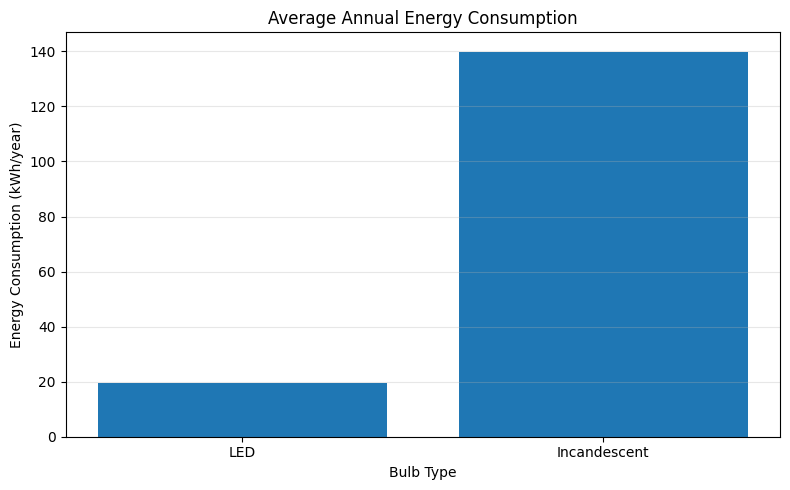

In [21]:
bulb_types = ["LED", "Incandescent"]

energy_values = [
    led_energy,
    incandescent_energy
]

plt.figure(figsize=(8, 5))

plt.bar(bulb_types, energy_values)

plt.title("Average Annual Energy Consumption")
plt.xlabel("Bulb Type")
plt.ylabel("Energy Consumption (kWh/year)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

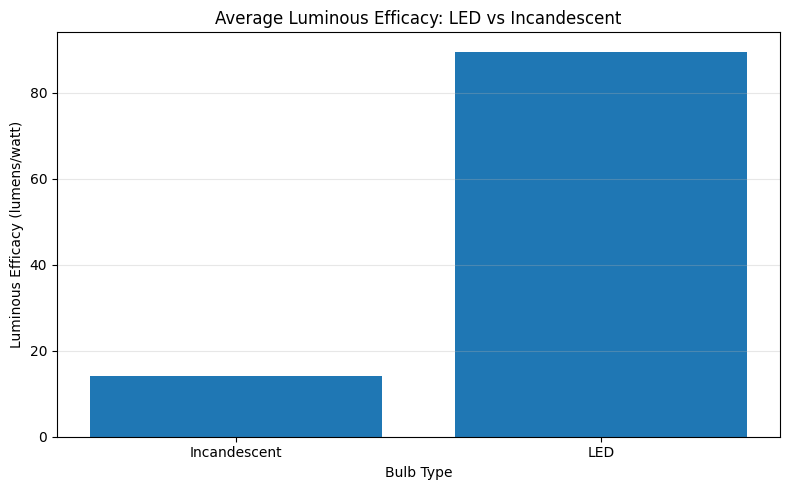

In [22]:
efficacy_values = cleaned_dataset.groupby("bulb_type")[
    "luminous_efficacy_lumens_per_watt"
].mean()

plt.figure(figsize=(8, 5))

plt.bar(efficacy_values.index, efficacy_values.values)

plt.title("Average Luminous Efficacy: LED vs Incandescent")
plt.xlabel("Bulb Type")
plt.ylabel("Luminous Efficacy (lumens/watt)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

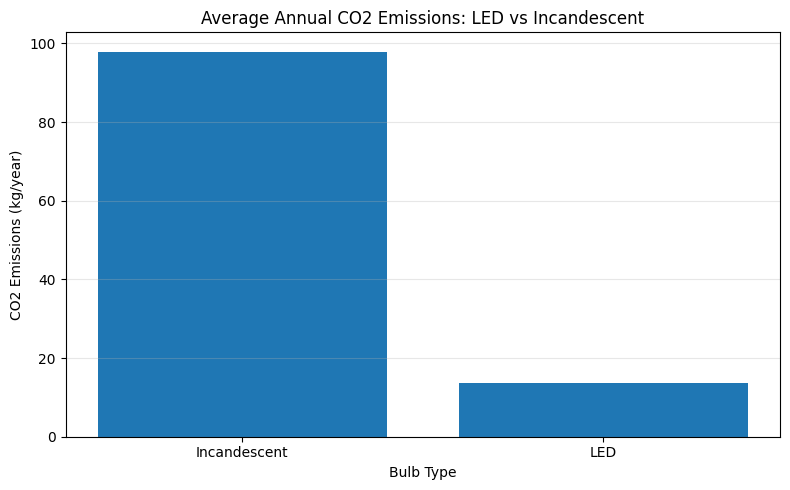

In [23]:
co2_values = cleaned_dataset.groupby("bulb_type")[
    "estimated_annual_co2_emissions_kg"
].mean()

plt.figure(figsize=(8, 5))

plt.bar(co2_values.index, co2_values.values)

plt.title("Average Annual CO2 Emissions: LED vs Incandescent")
plt.xlabel("Bulb Type")
plt.ylabel("CO2 Emissions (kg/year)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

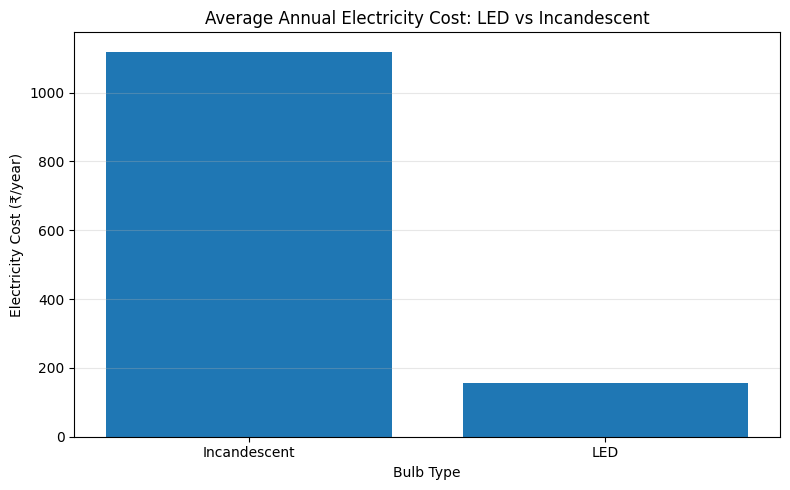

In [24]:
cost_values = cleaned_dataset.groupby("bulb_type")[
    "estimated_annual_electricity_cost_inr"
].mean()

plt.figure(figsize=(8, 5))

plt.bar(cost_values.index, cost_values.values)

plt.title("Average Annual Electricity Cost: LED vs Incandescent")
plt.xlabel("Bulb Type")
plt.ylabel("Electricity Cost (₹/year)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [25]:
comparison_table = cleaned_dataset.groupby("bulb_type").agg(
    Average_Brightness=("measured_brightness_lumens", "mean"),
    Average_Power=("power_rating_watts", "mean"),
    Average_Efficacy=("luminous_efficacy_lumens_per_watt", "mean"),
    Annual_Energy=("annual_energy_consumption_kwh", "mean"),
    Annual_Cost=("estimated_annual_electricity_cost_inr", "mean"),
    Annual_CO2=("estimated_annual_co2_emissions_kg", "mean")
).round(2)

comparison_table = comparison_table.T

print("LED vs Incandescent – Overall Comparison")
display(comparison_table)

LED vs Incandescent – Overall Comparison


bulb_type,Incandescent,LED
Average_Brightness,986.60,995.79
Average_Power,70.56,11.12
Average_Efficacy,14.02,89.63
Annual_Energy,139.91,19.70
Annual_Cost,1119.31,157.58
Annual_CO2,97.94,13.79


In [26]:
led_efficacy = comparison_table.loc[
    "Average_Efficacy", "LED"
]

incandescent_efficacy = comparison_table.loc[
    "Average_Efficacy", "Incandescent"
]

efficacy_improvement = (
    (led_efficacy - incandescent_efficacy)
    / incandescent_efficacy
) * 100

print(f"LED efficacy: {led_efficacy:.2f} lm/W")
print(f"Incandescent efficacy: {incandescent_efficacy:.2f} lm/W")
print(f"LED efficacy improvement: {efficacy_improvement:.2f}%")

LED efficacy: 89.63 lm/W
Incandescent efficacy: 14.02 lm/W
LED efficacy improvement: 539.30%


In [27]:
brightness_check = cleaned_dataset.groupby("bulb_type").agg(
    Average_Target_Brightness=("target_brightness_lumens", "mean"),
    Average_Measured_Brightness=("measured_brightness_lumens", "mean"),
    Minimum_Brightness=("measured_brightness_lumens", "min"),
    Maximum_Brightness=("measured_brightness_lumens", "max")
).round(2)

display(brightness_check)

,Average_Target_Brightness,Average_Measured_Brightness,Minimum_Brightness,Maximum_Brightness
bulb_type,,,,
Incandescent,987.5,986.60,361.4,1834.0
LED,987.5,995.79,390.8,2050.8


In [28]:
led_brightness = cleaned_dataset[
    cleaned_dataset["bulb_type"] == "LED"
]["measured_brightness_lumens"].mean()

incandescent_brightness = cleaned_dataset[
    cleaned_dataset["bulb_type"] == "Incandescent"
]["measured_brightness_lumens"].mean()

brightness_difference = (
    (led_brightness - incandescent_brightness)
    / incandescent_brightness
) * 100

print(f"LED average brightness: {led_brightness:.2f} lumens")
print(f"Incandescent average brightness: {incandescent_brightness:.2f} lumens")
print(f"Brightness difference: {brightness_difference:.2f}%")

LED average brightness: 995.79 lumens
Incandescent average brightness: 986.60 lumens
Brightness difference: 0.93%


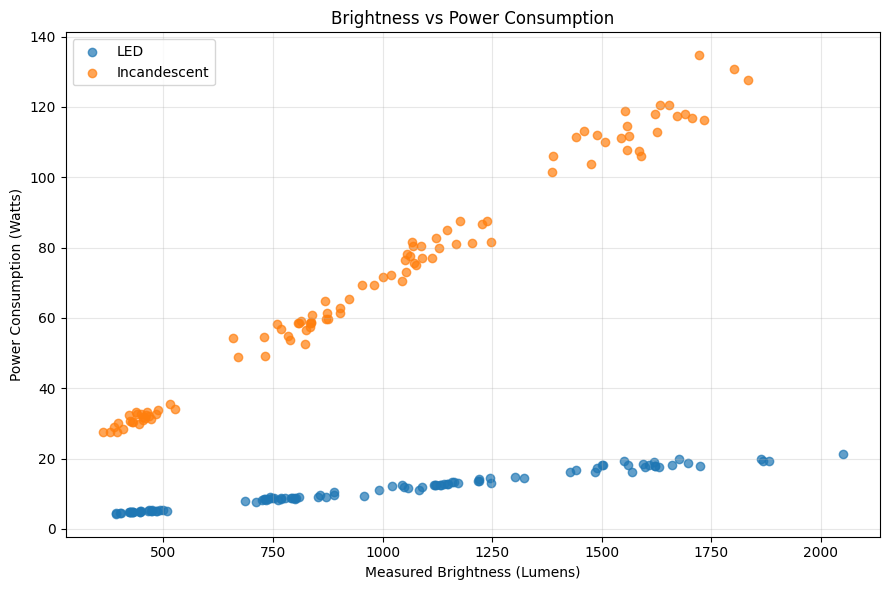

In [29]:
led_data = cleaned_dataset[
    cleaned_dataset["bulb_type"] == "LED"
]

incandescent_data = cleaned_dataset[
    cleaned_dataset["bulb_type"] == "Incandescent"
]

plt.figure(figsize=(9, 6))

plt.scatter(
    led_data["measured_brightness_lumens"],
    led_data["power_rating_watts"],
    label="LED",
    alpha=0.7
)

plt.scatter(
    incandescent_data["measured_brightness_lumens"],
    incandescent_data["power_rating_watts"],
    label="Incandescent",
    alpha=0.7
)

plt.title("Brightness vs Power Consumption")
plt.xlabel("Measured Brightness (Lumens)")
plt.ylabel("Power Consumption (Watts)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [30]:
comparison_table.to_csv(
    "../outputs/led_incandescent_comparison.csv"
)

print("Comparison results saved successfully!")

Comparison results saved successfully!


In [31]:
plt.gcf().savefig(
    "../outputs/brightness_vs_power.png",
    dpi=300,
    bbox_inches="tight"
)

print("Scatter plot saved successfully!")

Scatter plot saved successfully!


<Figure size 640x480 with 0 Axes>

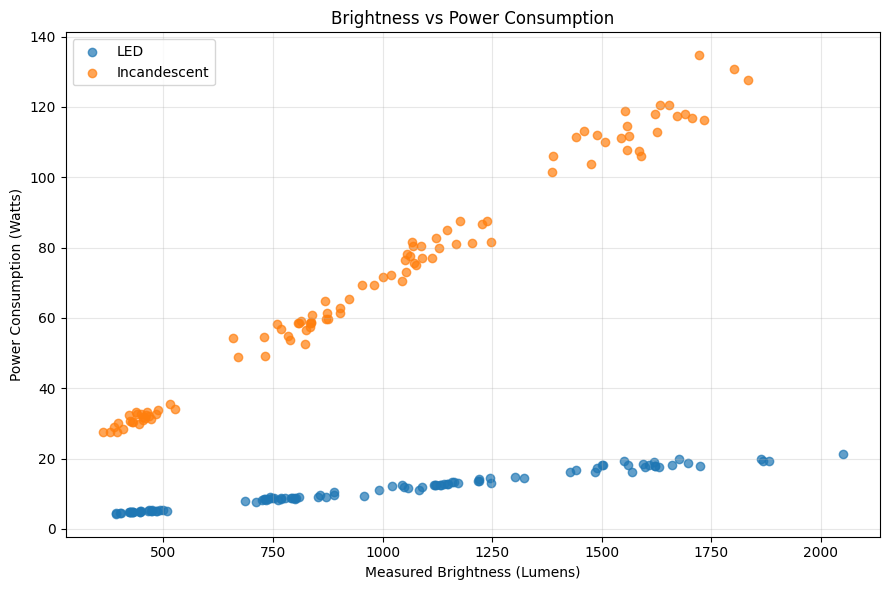

Scatter plot saved correctly!


In [32]:
plt.figure(figsize=(9, 6))

plt.scatter(
    led_data["measured_brightness_lumens"],
    led_data["power_rating_watts"],
    label="LED",
    alpha=0.7
)

plt.scatter(
    incandescent_data["measured_brightness_lumens"],
    incandescent_data["power_rating_watts"],
    label="Incandescent",
    alpha=0.7
)

plt.title("Brightness vs Power Consumption")
plt.xlabel("Measured Brightness (Lumens)")
plt.ylabel("Power Consumption (Watts)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

# Save before displaying
plt.savefig(
    "../outputs/brightness_vs_power.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Scatter plot saved correctly!")

In [33]:
import os

file_path = "../outputs/brightness_vs_power.png"

if os.path.exists(file_path):
    print("File exists!")
    print("File size:", round(os.path.getsize(file_path) / 1024, 2), "KB")
else:
    print("File not found!")

File exists!
File size: 224.5 KB


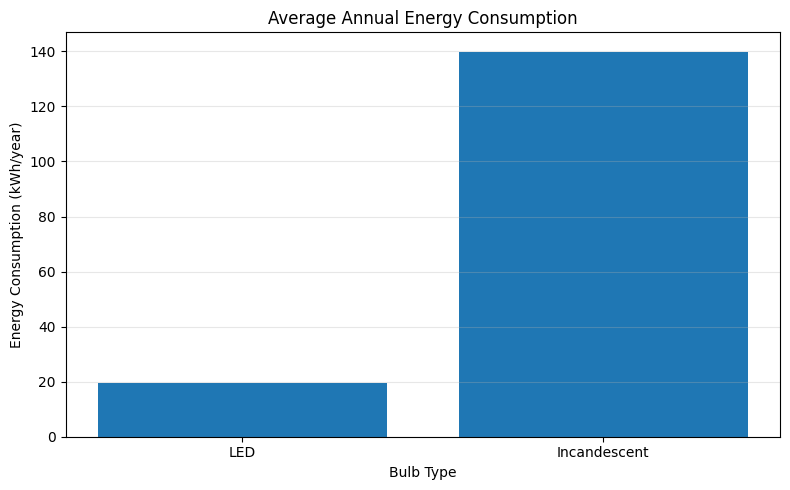

Annual energy graph saved!


In [34]:
plt.figure(figsize=(8, 5))

plt.bar(
    ["LED", "Incandescent"],
    [led_energy, incandescent_energy]
)

plt.title("Average Annual Energy Consumption")
plt.xlabel("Bulb Type")
plt.ylabel("Energy Consumption (kWh/year)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../outputs/annual_energy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Annual energy graph saved!")

In [35]:
import os

file_path = "../outputs/annual_energy_comparison.png"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    print("File size:", round(os.path.getsize(file_path) / 1024, 2), "KB")

File exists: True
File size: 76.76 KB


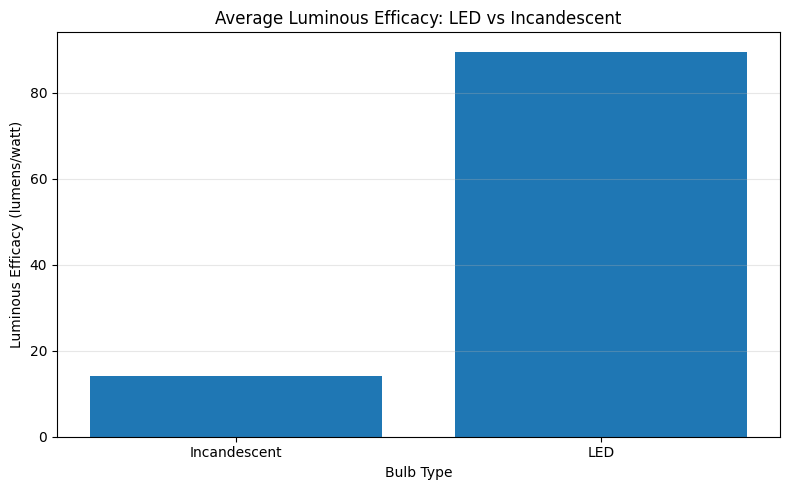

Luminous efficacy graph saved!


In [36]:
plt.figure(figsize=(8, 5))

plt.bar(efficacy_values.index, efficacy_values.values)

plt.title("Average Luminous Efficacy: LED vs Incandescent")
plt.xlabel("Bulb Type")
plt.ylabel("Luminous Efficacy (lumens/watt)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../outputs/luminous_efficacy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Luminous efficacy graph saved!")

In [37]:
import os

file_path = "../outputs/luminous_efficacy_comparison.png"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    print("File size:", round(os.path.getsize(file_path) / 1024, 2), "KB")

File exists: True
File size: 70.79 KB


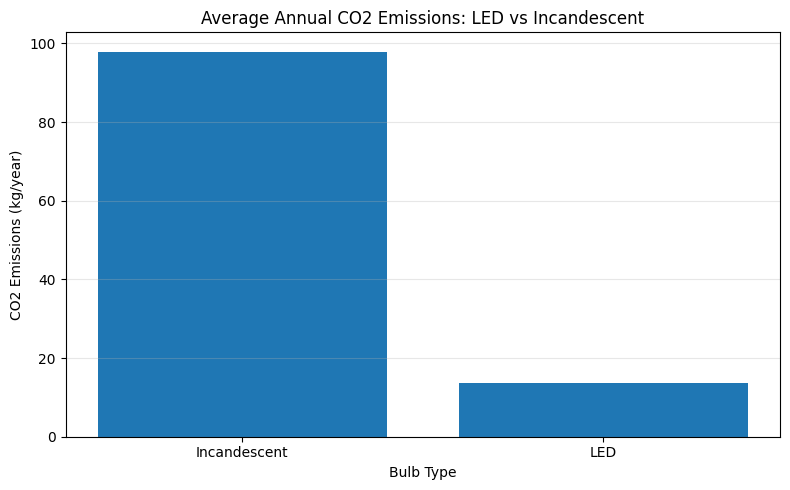

CO2 emissions graph saved!


In [38]:
plt.figure(figsize=(8, 5))

plt.bar(co2_values.index, co2_values.values)

plt.title("Average Annual CO2 Emissions: LED vs Incandescent")
plt.xlabel("Bulb Type")
plt.ylabel("CO2 Emissions (kg/year)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../outputs/co2_emissions_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("CO2 emissions graph saved!")

In [39]:
import os

file_path = "../outputs/co2_emissions_comparison.png"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    print("File size:", round(os.path.getsize(file_path) / 1024, 2), "KB")

File exists: True
File size: 73.54 KB


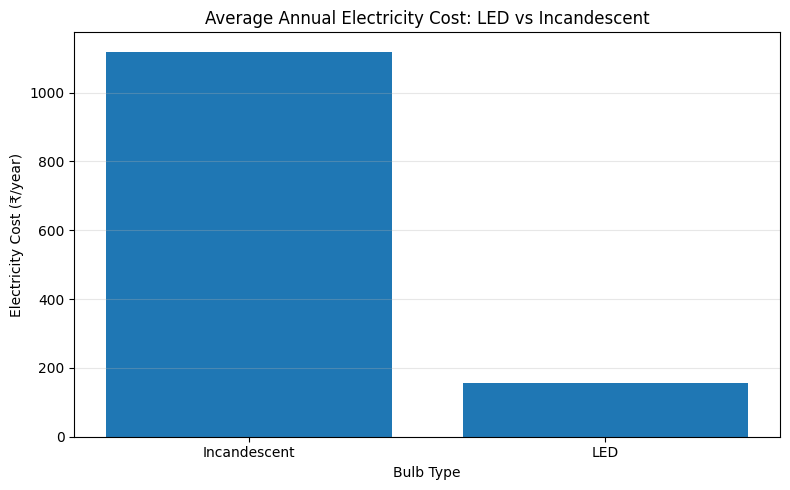

Electricity cost graph saved!


In [40]:
plt.figure(figsize=(8, 5))

plt.bar(cost_values.index, cost_values.values)

plt.title("Average Annual Electricity Cost: LED vs Incandescent")
plt.xlabel("Bulb Type")
plt.ylabel("Electricity Cost (₹/year)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../outputs/electricity_cost_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Electricity cost graph saved!")

In [41]:
import os

file_path = "../outputs/electricity_cost_comparison.png"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    print("File size:", round(os.path.getsize(file_path) / 1024, 2), "KB")

File exists: True
File size: 73.93 KB
